# 11. Income Damage Feedback

I use this notebook to check how pollution damage affects income over time. The tests compare damage applied to current income only with damage that also carries into future productivity. I keep the quadratic development cost, starting conditions, pollution processes, mitigation costs, and fixed policies unchanged. No agents are trained.

## Income update

For region *i* in year *t*, the environment calculates gross income as:

`G[t] = B[t-1] * (1 + g) * (F[EDI[t]] / F[EDI[t-1]])`

`B[t-1]` is the income base carried from the previous year, `g` is the regional growth rate, and `F` is the EDI income factor. Current environmental damage gives net income `N[t] = G[t] * (1 - D[t])`, which is added to currency after action costs. The current implementation then sets `B[t] = N[t]`. This means an income loss from damage reduces the base used to calculate later gross income.

I test a persistence parameter `p`: `B[t] = G[t] * (1 - p * D[t])`. At `p=0`, damage reduces this year's currency income but does not carry into future gross income. At `p=1`, it matches the current implementation. `p=0.5` is an intermediate scenario. This is a model sensitivity test, not an empirically estimated persistence rate.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from study_3_pollutant_dynamics.config import EnvironmentConfig
from study_3_pollutant_dynamics.integrated_environment import Study3IntegratedEnvironment
from study_3_pollutant_dynamics.economic_parameters import REGIONAL_ECONOMIC_PARAMETERS
from study_3_pollutant_dynamics.policy_evaluation import (run_fixed_policy_episode, summarize_integrated_episode)
from study_3_pollutant_dynamics.scenario_parameters import get_parameters

## Test settings

All comparisons use the same seed, 60-year horizon, and quadratic development costs. The fixed policies are development-only and balanced. Damage strength is tested by multiplying the four reference damage rates while keeping their reference lag settings unchanged. These strengths are synthetic sensitivity values, not measured ranges.

In [2]:
def run_damage_case(policy_name, persistence, rate_multiplier):
    config = EnvironmentConfig(get_parameters(episode_steps=HORIZON))
    environment = Study3IntegratedEnvironment(config, starting_currency_multiplier=1.0,
                                              development_cost_shape=DEVELOPMENT_COST_SHAPE,
                                              income_damage_multiplier=rate_multiplier,
                                              income_damage_persistence=persistence)

    trajectory, terminated, truncated = run_fixed_policy_episode(policy_name, environment, seed=SEED)
    summary = summarize_integrated_episode(policy_name, trajectory, environment)
    return environment, trajectory, summary

In [3]:
HORIZON = 60
SEED = 0
DEVELOPMENT_COST_SHAPE = "quadratic"
POLICIES = ["development_only", "balanced"]
PERSISTENCE_VALUES = [0.0, 0.5, 1.0]
DAMAGE_RATE_MULTIPLIERS = [0.25, 0.5, 1.0, 1.5, 2.0]
INCOME_COLLAPSE_RATIO = 0.10

## What damage does to next year?s income

I first compare the South under the current reference damage rates. The table reports gross income, current damage, net income, the next-year income base, development, mitigation, and currency at selected years. This makes the carry-forward step visible.

In [4]:
mechanism_rows = []
mechanism_trajectory = None
mechanism_environment = None

for policy_name in POLICIES:
    environment, trajectory, summary = run_damage_case(policy_name, 1.0, 1.0)

    if policy_name == "balanced":
        mechanism_trajectory = trajectory
        mechanism_environment = environment

    for info in trajectory:
        year = info["regional_economy"][0]["year"]

        if year in [1, 5, 10, 15, 20, 30, 40, 50, 60]:
            for region_result in info["regional_economy"]:
                if region_result["region"] == "South":
                    mechanism_rows.append({
                        "policy": policy_name,
                        "year": year,
                        "EDI": region_result["EDI"],
                        "gross_income": region_result["gross_income"],
                        "damage_fraction": region_result["damage_fraction"],
                        "income_damage": region_result["gross_income"] - region_result["net_income"],
                        "net_income": region_result["net_income"],
                        "next_year_income_base": region_result["next_year_income_base"],
                        "development_spending": region_result["development_cost"],
                        "mitigation_spending": region_result["investment_cost"],
                        "currency": region_result["currency"],
                    })
mechanism_results = pd.DataFrame(mechanism_rows)
display(mechanism_results.round(3))

,policy,year,EDI,gross_income,damage_fraction,income_damage,net_income,next_year_income_base,development_spending,mitigation_spending,currency
0,development_only,1,56.0,51.000,0.008,0.395,50.605,75.759,25.000,0.0,475.605
1,development_only,5,60.0,83.078,0.018,1.524,81.553,82.494,29.642,0.0,681.258
2,development_only,10,65.0,91.833,0.033,2.996,88.837,91.013,36.000,0.0,944.149
3,development_only,15,70.0,100.150,0.050,5.030,95.120,99.024,42.975,0.0,1206.990
4,development_only,20,75.0,107.613,0.071,7.604,100.009,106.128,50.568,0.0,1460.477
5,development_only,30,85.0,116.803,0.119,13.849,102.953,113.995,67.605,0.0,1891.016
6,development_only,40,95.0,115.155,0.174,20.007,95.148,111.772,87.111,0.0,2101.749
7,development_only,50,100.0,108.478,0.212,23.018,85.460,105.979,0.000,0.0,2523.573
8,development_only,60,100.0,102.361,0.217,22.247,80.113,99.492,0.000,0.0,3351.989
9,balanced,1,56.0,51.000,0.008,0.395,50.605,75.759,25.000,200.0,275.605


## Current-income damage versus persistent damage

The next table compares persistence values of 0, 0.5, and 1 under the reference damage rates. It reports final EDI and currency, cumulative income damage, net income, and development and mitigation spending. The regional results show whether any policy-level average hides a region with much worse outcomes.

In [5]:
persistence_summary_rows = []
persistence_region_rows = []

for persistence in PERSISTENCE_VALUES:
    for policy_name in POLICIES:
        environment, trajectory, summary = run_damage_case(policy_name, persistence, 1.0)
        cumulative_gross = 0.0
        cumulative_net = 0.0
        cumulative_damage = 0.0

        for info in trajectory:
            for region_result in info["regional_economy"]:
                gross_income = region_result["gross_income"]
                net_income = region_result["net_income"]
                cumulative_gross += gross_income
                cumulative_net += net_income
                cumulative_damage += gross_income - net_income

        summary_row = {
            "persistence": persistence,
            "policy": policy_name,
            "final_mean_EDI": summary["final_mean_EDI"],
            "final_min_EDI": summary["final_min_EDI"],
            "cumulative_gross_income": cumulative_gross,
            "cumulative_net_income": cumulative_net,
            "direct_income_damage": cumulative_damage,
            "development_spending": summary["development_spending"],
            "mitigation_spending": summary["mitigation_spending"],
            "final_mean_currency": summary["final_mean_currency"],
            "unaffordable_development_attempts": summary["unaffordable_development_attempts"],
        }
        persistence_summary_rows.append(summary_row)

        for region_index, region in enumerate(environment.regions):
            final_net_income = trajectory[-1]["regional_economy"][region_index]["net_income"]
            starting_income = REGIONAL_ECONOMIC_PARAMETERS[region_index]["annual_income"]
            income_ratio = final_net_income / starting_income
            persistence_region_rows.append({
                "persistence": persistence,
                "policy": policy_name,
                "region": region,
                "final_EDI": environment.edi[region_index],
                "final_net_income": final_net_income,
                "final_income_ratio": income_ratio,
                "final_currency": environment.currency[region_index],
                "income_below_10pct": income_ratio < INCOME_COLLAPSE_RATIO,
            })

persistence_summary = pd.DataFrame(persistence_summary_rows)
display(persistence_summary.round(3))

,persistence,policy,final_mean_EDI,final_min_EDI,cumulative_gross_income,cumulative_net_income,direct_income_damage,development_spending,mitigation_spending,final_mean_currency,unaffordable_development_attempts
0,0.0,development_only,100.0,100.0,36723.030,33113.262,3609.768,8017.169,0.0,6899.023,0
1,0.0,balanced,100.0,100.0,36723.030,35580.076,1142.954,8017.169,9600.0,5115.727,0
2,0.5,development_only,100.0,100.0,30884.715,28125.169,2759.545,8017.169,0.0,5652.000,0
3,0.5,balanced,100.0,100.0,34053.883,33040.209,1013.674,8017.169,9600.0,4480.760,0
4,1.0,development_only,100.0,100.0,26278.961,24165.780,2113.181,8017.169,0.0,4662.153,0
5,1.0,balanced,100.0,100.0,31668.517,30768.476,900.041,8017.169,9600.0,3912.827,0


In [6]:
persistence_regions = pd.DataFrame(persistence_region_rows)
display(persistence_regions.round(3))

,persistence,policy,region,final_EDI,final_net_income,final_income_ratio,final_currency,income_below_10pct
0,0.0,development_only,Northeast,100.0,244.147,3.756,8006.755,False
1,0.0,development_only,Midwest,100.0,179.001,3.255,5415.831,False
2,0.0,development_only,South,100.0,197.746,3.955,5727.267,False
3,0.0,development_only,West,100.0,245.614,3.275,8446.240,False
4,0.0,balanced,Northeast,100.0,248.214,3.819,5690.746,False
5,0.0,balanced,Midwest,100.0,224.829,4.088,4347.375,False
6,0.0,balanced,South,100.0,235.363,4.707,4309.856,False
7,0.0,balanced,West,100.0,248.949,3.319,6114.930,False
8,0.5,development_only,Northeast,100.0,173.345,2.667,6889.021,False
9,0.5,development_only,Midwest,100.0,110.524,2.010,3997.294,False


## Regional sensitivity under reference damage

Starting income, currency, growth, EDI, and regional pollutant multipliers are different assumptions in this model. I compare final income with each region's own starting income and inspect pollutant-specific damage fractions. This separates low starting resources from exposure and damage differences.

In [7]:
regional_reference_rows = []

for policy_name in POLICIES:
    environment, trajectory, summary = run_damage_case(policy_name, 1.0, 1.0)
    damage_sums = {}

    for region in environment.regions:
        damage_sums[region] = {"PM2.5": 0.0, "CO2": 0.0, "Nitrate-N": 0.0, "Lead": 0.0}

    for info in trajectory:
        for region_index, region_result in enumerate(info["regional_economy"]):
            region = environment.regions[region_index]
            for pollutant, damage_fraction in region_result["damage_by_pollutant"].items():
                damage_sums[region][pollutant] += damage_fraction

    for region_index, region in enumerate(environment.regions):
        parameters = REGIONAL_ECONOMIC_PARAMETERS[region_index]
        final_result = trajectory[-1]["regional_economy"][region_index]
        initial_income = parameters["annual_income"]
        income_ratio = final_result["net_income"] / initial_income
        row = {
            "policy": policy_name,
            "region": region,
            "initial_EDI": parameters["initial_edi"],
            "initial_currency": parameters["initial_currency"],
            "initial_income": initial_income,
            "growth_rate": parameters["annual_income_growth_rate"],
            "final_EDI": environment.edi[region_index],
            "final_net_income": final_result["net_income"],
            "final_income_ratio": income_ratio,
            "final_currency": environment.currency[region_index],
            "development_failures": environment.unaffordable_development_attempts[region_index],
        }

        for pollutant in damage_sums[region]:
            row[f"mean_{pollutant}_damage_fraction"] = damage_sums[region][pollutant] / HORIZON
        regional_reference_rows.append(row)

regional_reference = pd.DataFrame(regional_reference_rows)
display(regional_reference.round(4))

,policy,region,initial_EDI,initial_currency,initial_income,growth_rate,final_EDI,final_net_income,final_income_ratio,final_currency,development_failures,mean_PM2.5_damage_fraction,mean_CO2_damage_fraction,mean_Nitrate-N_damage_fraction,mean_Lead_damage_fraction
0,development_only,Northeast,70.0,700.0,65.0,0.015,100.0,122.7119,1.8879,5982.9230,0,0.0001,0.0058,0.0005,0.0068
1,development_only,Midwest,60.0,550.0,55.0,0.012,100.0,66.1698,1.2031,2891.5186,0,0.0001,0.0058,0.1763,0.0102
2,development_only,South,55.0,450.0,50.0,0.020,100.0,80.1134,1.6023,3351.9888,0,0.0001,0.0058,0.1106,0.0080
3,development_only,West,75.0,800.0,75.0,0.018,100.0,123.8193,1.6509,6422.1808,0,0.0000,0.0058,0.0000,0.0060
4,balanced,Northeast,70.0,700.0,65.0,0.015,100.0,179.0597,2.7548,4622.3010,0,0.0000,0.0056,0.0000,0.0000
5,balanced,Midwest,60.0,550.0,55.0,0.012,100.0,147.3454,2.6790,2929.0085,0,0.0000,0.0056,0.0537,0.0000
6,balanced,South,55.0,450.0,50.0,0.020,100.0,160.2090,3.2042,3056.4500,0,0.0000,0.0056,0.0259,0.0000
7,balanced,West,75.0,800.0,75.0,0.018,100.0,179.5901,2.3945,5043.5475,0,0.0000,0.0056,0.0000,0.0000


## Damage-strength sensitivity

I scale only the reference damage rates, leaving reference lags and all pollutant and economic mechanics unchanged. The table reports final income relative to each region's starting income, final EDI, and whether final income falls below 10% of its starting level.

In [8]:
strength_rows = []

for rate_multiplier in DAMAGE_RATE_MULTIPLIERS:
    for persistence in PERSISTENCE_VALUES:
        for policy_name in POLICIES:
            environment, trajectory, summary = run_damage_case(policy_name, persistence, rate_multiplier)
            for region_index, region in enumerate(environment.regions):
                final_result = trajectory[-1]["regional_economy"][region_index]
                starting_income = REGIONAL_ECONOMIC_PARAMETERS[region_index]["annual_income"]
                income_ratio = final_result["net_income"] / starting_income

                strength_rows.append({
                    "damage_rate_multiplier": rate_multiplier,
                    "persistence": persistence,
                    "policy": policy_name,
                    "region": region,
                    "final_EDI": environment.edi[region_index],
                    "final_income_ratio": income_ratio,
                    "final_currency": environment.currency[region_index],
                    "development_failures": environment.unaffordable_development_attempts[region_index],
                    "income_below_10pct": income_ratio < INCOME_COLLAPSE_RATIO,
                })

In [9]:
strength_results = pd.DataFrame(strength_rows)
strength_summary = strength_results.groupby(["damage_rate_multiplier", "persistence", "policy"]).agg(
    mean_final_EDI=("final_EDI", "mean"),
    mean_final_income_ratio=("final_income_ratio", "mean"),
    minimum_final_income_ratio=("final_income_ratio", "min"),
    regions_below_10pct=("income_below_10pct", "sum"),
    development_failures=("development_failures", "sum"),
).reset_index()
display(strength_summary.round(3))

,damage_rate_multiplier,persistence,policy,mean_final_EDI,mean_final_income_ratio,minimum_final_income_ratio,regions_below_10pct,development_failures
0,0.25,0.0,balanced,100.0,4.152,3.351,0,0
1,0.25,0.0,development_only,100.0,4.031,3.340,0,0
2,0.25,0.5,balanced,100.0,3.965,3.217,0,0
3,0.25,0.5,development_only,100.0,3.635,3.066,0,0
4,0.25,1.0,balanced,100.0,3.786,3.089,0,0
5,0.25,1.0,development_only,100.0,3.277,2.814,0,0
6,0.50,0.0,balanced,100.0,4.094,3.341,0,0
7,0.50,0.0,development_only,100.0,3.863,3.318,0,0
8,0.50,0.5,balanced,100.0,3.734,3.079,0,0
9,0.50,0.5,development_only,100.0,3.149,2.797,0,0


In [10]:
high_damage_regions = strength_results[(strength_results["damage_rate_multiplier"] == 2.0)
                                       & (strength_results["persistence"] == 1.0)]
display(high_damage_regions.round(3))

,damage_rate_multiplier,persistence,policy,region,final_EDI,final_income_ratio,final_currency,development_failures,income_below_10pct
112,2.0,1.0,development_only,Northeast,100.0,0.921,4578.348,0,False
113,2.0,1.0,development_only,Midwest,100.0,0.318,984.539,0,False
114,2.0,1.0,development_only,South,100.0,0.508,1550.732,0,False
115,2.0,1.0,development_only,West,100.0,0.811,5021.914,0,False
116,2.0,1.0,balanced,Northeast,100.0,1.962,3707.988,0,False
117,2.0,1.0,balanced,Midwest,100.0,1.575,1488.875,0,False
118,2.0,1.0,balanced,South,100.0,2.032,1860.428,0,False
119,2.0,1.0,balanced,West,100.0,1.705,4126.766,0,False


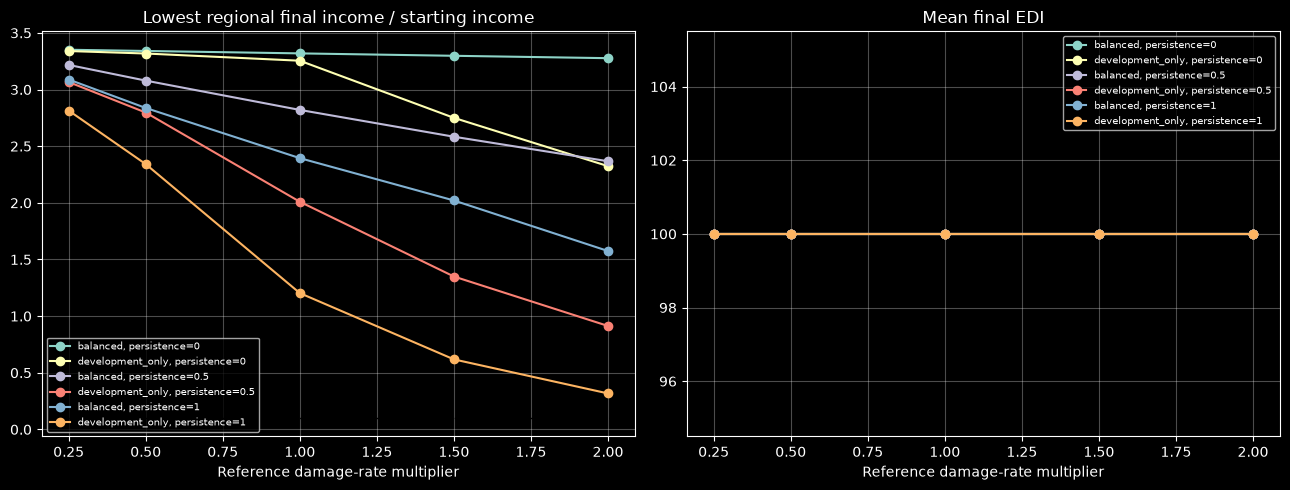

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for (persistence, policy_name), policy_rows in strength_summary.groupby(["persistence", "policy"], sort=False):
    label = f"{policy_name}, persistence={persistence:g}"
    axes[0].plot(policy_rows["damage_rate_multiplier"], policy_rows["minimum_final_income_ratio"], marker="o", label=label)
    axes[1].plot(policy_rows["damage_rate_multiplier"], policy_rows["mean_final_EDI"], marker="o", label=label)

axes[0].axhline(INCOME_COLLAPSE_RATIO, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Lowest regional final income / starting income")
axes[1].set_title("Mean final EDI")

for axis in axes:
    axis.set_xlabel("Reference damage-rate multiplier")
    axis.grid(alpha=0.3)

axes[0].legend(fontsize=7)
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

## What the results show

The income base is the compounding link. With persistence set to 1, this year's net income becomes next year's starting base. At persistence 0, damage still reduces cash income this year, but next year's gross income is based on this year's undamaged gross income. A value of 0.5 carries half of the current damage into the next income base.

Under reference damage, all four regions reach EDI 100 by year 60 with both fixed policies, even at full persistence. Increasing persistence reduces cumulative net income, but does not create development failures in these runs. When damage rates are doubled, the lowest final income is about 32% of its starting level; no region falls below the 10% near-zero marker, and no development attempts fail. Collapse does not occur across the tested rate and persistence range. These rates are synthetic sensitivity values, not an empirical plausibility interval.

The South is not the most damage-sensitive region in the reference run. It starts with the lowest currency (450) and income (50), but its 2.0% annual growth assumption is the highest. The Midwest has the lowest final-income ratio under development-only (1.20 times its starting income), along with the largest modeled nitrate and lead damage fractions. Its assumed nitrate and lead emission multipliers are also the highest. These regional multipliers are provisional assumptions, so the difference identifies a model driver rather than a real-world regional ranking.

The main caution is that the income base retains the full damage loss when persistence is 1. That is a strong modeling choice, but these runs do not show near-guaranteed collapse. Before changing it, the next decision is whether environmental damage should permanently lower the income-growth base, reduce only current disposable income, or have a partial and recoverable productivity effect. The notebook exposes that choice for later review; it does not calibrate it.